# 최소 Recall 55% — 진행 중인 개선 실험

**아직 세 모델·다섯 시나리오의 조건을 모두 통과한 새 릴리스는 없다. 최신 검증 모델은 v6다.**

목표는 각 모델의 각 시나리오에서 Recall ≥55%, Accuracy·Precision·F1은 v6 이상, 오탐률 <5%다. 전체 평균으로 미달 시나리오를 가리지 않는다. 이 노트북은 실패한 후보와 새 피처의 가능성까지 구분해서 보여주는 중간 연구 기록이다.

In [1]:
from pathlib import Path
import json,numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents]if(p/'reports/shared_model_v7/protocol.json').exists())
read=lambda p:json.loads(p.read_text(encoding='utf-8'))
OUT=ROOT/'reports/shared_model_v7';BASE=ROOT/'reports/shared_model_v6/release'
s=read(BASE/'summary.json');alg=['if','kmeans','lof'];names=['IF','K-means','LOF']
tasks=['individual_delay','group_delay','time_burst','input_stop','gradual_degradation']
labels=['개별 지연','집단 지연','시간대 폭주','입력 중단','점진적 악화']
plt.rcParams.update({'font.family':'Malgun Gothic','axes.unicode_minus':False,'axes.spines.top':False,'axes.spines.right':False,'font.size':11})
rows=[{'시나리오':labels[tasks.index(d['dataset'])],**r}for d in s['datasets']for r in d['metrics']]
table=pd.DataFrame(rows)

## 1. 현재 모델은 어디가 부족한가

아래는 **v6 전체 1,927,972개 판정**이다. 빨간 점선 아래 막대가 새 목표 미달이다. v6 전체 합산 Recall은 세 모델 모두 60% 이상이지만, 각 시나리오까지 모두 55%인 것은 아니다.

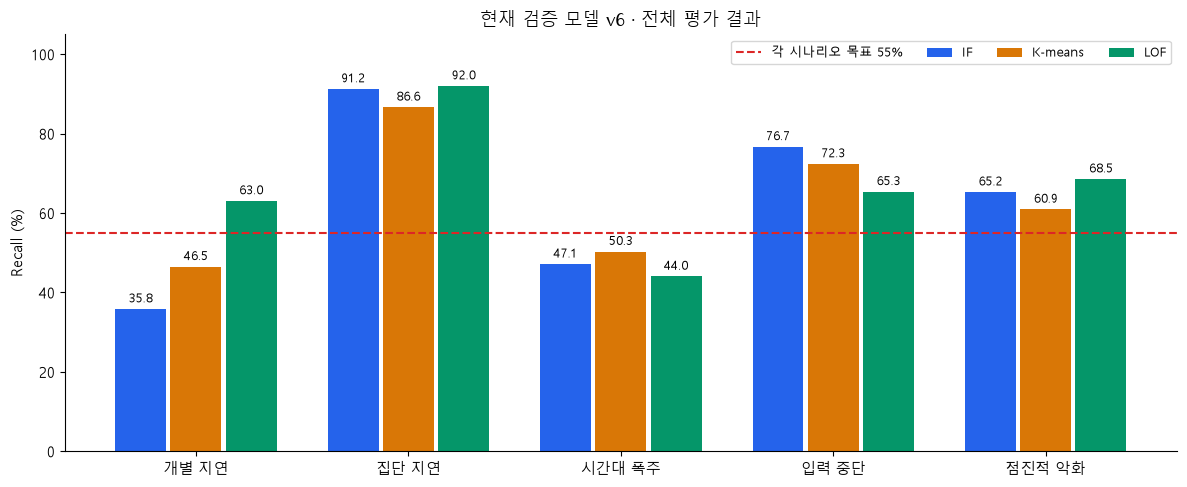

,시나리오,method,accuracy,precision,recall,f1,normal_false_positive_rate
0,개별 지연,if,94.507,98.647,35.794,52.528,0.046
1,개별 지연,kmeans,95.294,96.101,46.456,62.634,0.175
2,개별 지연,lof,96.554,94.579,63.028,75.645,0.335
3,집단 지연,if,95.834,82.968,91.229,86.903,3.344
4,집단 지연,kmeans,95.553,84.425,86.623,85.510,2.853
5,집단 지연,lof,95.331,80.139,91.971,85.648,4.069
6,시간대 폭주,if,93.166,78.998,47.099,59.014,1.461
7,시간대 폭주,kmeans,93.817,84.158,50.265,62.939,1.104
8,시간대 폭주,lof,93.047,80.622,44.020,56.947,1.234
9,입력 중단,if,95.588,94.593,76.663,84.690,0.830


In [2]:
fig,ax=plt.subplots(figsize=(12,5));x=np.arange(5)
for i,(a,name,color)in enumerate(zip(alg,names,['#2563eb','#d97706','#059669'])):
    values=[next(r for r in d['metrics']if r['method']==a)['recall']*100 for d in s['datasets']]
    bars=ax.bar(x+(i-1)*.26,values,width=.24,label=name,color=color);ax.bar_label(bars,fmt='%.1f',padding=3,fontsize=9)
ax.axhline(55,color='#dc2626',linestyle='--',label='각 시나리오 목표 55%')
ax.set(xticks=x,xticklabels=labels,ylim=(0,105),ylabel='Recall (%)',title='현재 검증 모델 v6 · 전체 평가 결과');ax.legend(ncol=4,fontsize=9)
fig.tight_layout();display(fig);plt.close(fig)
metrics=['accuracy','precision','recall','f1','normal_false_positive_rate']
view=table[['시나리오','method',*metrics]].copy();view[metrics]=view[metrics]*100
display(view.round(3))

## 2. 성능을 유지한다는 뜻

예를 들어 IF의 개별 지연은 Precision이 이미 약 98.65%다. Recall을 55%로 올려도 Precision이 90%로 내려가면 **실패**다. 입력 중단·집단 지연의 기존 성능을 낮춰 전체 숫자만 올려도 실패다. 세 모델 × 다섯 시나리오의 조건을 개별 검사한다.

기존 점수의 전역 경보선만 낮추는 방법, 정상 소스 확대, 시간창 누적, 거리·군집 기하와 이웃 수 변경, 정상 소요시간 회귀 등은 아직 이 조건을 동시에 충족하지 못했다. 미채택 후보를 최신 모델로 교체하지 않았다.

## 3. 새 단서 — 단순히 오래 걸렸는가 + 비슷한 정상 실행과도 다른가

기존의 상위 꼬리 피처만 쓰면 정상 소요시간이 여러 유형으로 나뉜 경우 **유형 사이의 빈 구간**을 놓칠 수 있다. 새 피처는 같은 Adapter·Process의 정상 사례를 우선 찾고 소요시간과 처리 건수의 최근 평균을 함께 비교한다. 가까운 정상 사례와의 거리 및 기존 상위 꼬리 근거를 **둘 다** 보도록 연속 수치로 결합했다.

정상 통계표는 평가 데이터로 만들지 않았다. 기존 감사된 정상 source 후보를 사용했다. 일부 실험에서는 정상 학습 행이 자기 자신을 가장 가까운 이웃으로 찾는 편향을 막기 위해 같은 사례를 참조에서 제외했다.

In [3]:
p=read(OUT/'point_full_diagnostic.json');r=p['best_high_precision_55Recall']
if r:
    display(pd.DataFrame([{'분석':'새 피처만의 구분 가능성 — IF/K-means/LOF 성능 아님',**{k:100*r[k]for k in ['accuracy','precision','recall','f1','normal_false_positive_rate']},'TP':r['tp'],'FP':r['fp'],'FN':r['fn'],'TN':r['tn']}]).round(4))
    display(Markdown(f"평가 범위: 개별 지연 정상·이상 **5,000쌍 전체**, 총 {p['rows']:,}개 분 판정."))
else:display(Markdown('전체 사례에서 높은 Precision과 Recall 55%를 함께 만족한 피처 기준 없음.'))

,분석,accuracy,precision,recall,f1,normal_false_positive_rate,TP,FP,FN,TN
0,새 피처만의 구분 가능성 — IF/K-means/LOF 성능 아님,98.4679,98.648,83.0944,90.2057,0.1057,4232,58,861,54833


평가 범위: 개별 지연 정상·이상 **5,000쌍 전체**, 총 59,984개 분 판정.

**위 숫자는 세 모델의 새 성능표가 아니다.** 피처의 정상 분위수 후보 중 전체 재사용 연구 결과를 보고 고른 분석값이다. 일부 전체 정답도 살펴봤으므로 독립 블라인드 성능으로 보고하지 않는다. 이 구분 가능성을 실제 모델 점수에 반영하면서 다른 시나리오를 유지해야 한다.

## 4. 시간대 폭주는 왜 아직 어려운가

최근 1·2·3·5·8분의 요청 수를, 그보다 앞선 관측과 과거 시간대의 정상 이력에 비교하는 변화 피처도 실험했다. 현재 시점까지의 로그만 사용하며 미래 로그나 실제 장애 종료 시각은 보지 않는다.

오래 기억하면 폭주 중간의 조용한 분을 잡을 수 있지만, 회복한 뒤에도 울리는 오탐이 늘 수 있다. 요청 수 변화 피처 하나의 개선을 최종 모델 Precision 개선이라고 단정할 수 없다.

In [4]:
p=read(OUT/'scan_diagnostics.json');out=[]
for r in p['results']:
    if r['task']!='time_burst':continue
    m=r['oracle_P_at_R55'];out.append({'피처':r['feature'],'ROC AUC':r['ROCAUC'],'Recall55·FPR5를 만족한 진단 기준 Precision %':None if m is None else m['precision']*100})
display(pd.DataFrame(out).round(3))

,피처,ROC AUC,Recall55·FPR5를 만족한 진단 기준 Precision %
0,count_scan_1m,0.722,NaN
1,count_scan_3m,0.786,63.523
2,count_scan_8m,0.841,56.242
3,count_scan_peak,0.903,70.493
4,count_scan_memory_3m,0.919,63.662
5,count_scan_memory_5m,0.907,NaN
6,count_scan_memory_8m,0.887,NaN


## 5. 모델에 반영하는 단계

- 정상 기준을 조건별로 보정하는 방법과 새 피처로 모델을 다시 학습하는 방법을 분리해 비교한다.
- 최근 완료 이력이 충분하지 않을 때만 새 개별 지연 피처를 반영하는 방식도 검증 중이다. 이력 부족은 실제 과거 완료 수로 계산하며 시나리오 이름으로 분기하지 않는다.
- 최종 후보는 채택 전에 **세 모델 × 다섯 시나리오 전체**를 다시 평가한다. 정답 구간 확장·미래 참조·데이터 난이도 변경으로 통과시키지 않는다.
- `evaluate.py`는 후보 파일과 경보선을 고정한 뒤 전체 사례를 평가하며, 실패한 결과를 자동으로 릴리스하지 않는다.

## 6. 현재 모델별 강점과 검증 상태

현재 v6에서는 IF가 집단 지연·입력 중단 F1, K-means가 폭주 F1·낮은 전체 오탐률, LOF가 개별 지연 F1에서 상대적으로 낫다. 점진적 악화는 IF와 LOF가 거의 비슷하다. 새 후보의 강점은 목표를 통과한 전체 평가 결과로 다시 확인해야 한다. 일부 모델을 고의로 약화해 차이를 만들지 않는다.

새 피처의 미래 비참조, paired 정상·이상 스트림 상태 초기화, 연속 분 입력, 시나리오별 비퇴보 범위와 Precision 교환 탈락을 테스트했다. 테스트 통과는 모델 성능 목표 달성을 뜻하지 않는다. 아직 v7 최종 result.ipynb·릴리스·Notion 업데이트는 하지 않았다.

## 7. 추가 요청한 역할을 위한 실험 — 아직 달성 아님

| 목표 모델 | 강화할 정보 |
|---|---|
| IF → 개별 지연 | 한 실행의 소요시간 꼬리와 비슷한 정상 실행까지의 거리 |
| K-means → 집단 지연 | 최근 여러 실행의 평균 지연·지연 지속·완료 규모 |
| LOF → 점진적 악화 | 최근 최대 8개 완료 관측 분의 잔차 궤적·기울기·증가 지속 |

**기존 지표 제약을 모두 통과한 다음에** 목표 시나리오 F1을 우선 비교하고 Precision·Recall도 공개한다. 다른 모델을 약화해 순위를 만들지 않는다. 세 모델의 전체 재평가에서 실제 우위가 확인되기 전까지는 원하는 역할을 달성했다고 표현하지 않는다.

## 8. 첫 전체 재평가 — 개선은 있으나 채택 조건 미달

기존 **5개 시나리오 각 5,000쌍 전체**를 재평가했다. v6 원 추정기에 정상 소요시간·요청 수 통계 점수와 관측 집단별 경보 기준을 결합한 후보다. **순수 IF/K-means/LOF만의 개선으로 해석하면 안 된다.** 동일한 벤치마크를 반복 사용한 연구 결과이며 외부 블라인드 성능이 아니다.

시간대 폭주 Recall이 세 모델 모두 55% 미만이고 일부 시나리오의 Precision·오탐률도 나빠졌다. 따라서 **기존 모델을 교체하지 않았다.**

In [5]:
candidate=read(OUT/'attempt_exact_counts01/summary.json')
comparison=[]
for b,d in zip(s['datasets'],candidate['datasets']):
    for a in alg:
        old=next(r for r in b['metrics']if r['method']==a);new=next(r for r in d['metrics']if r['method']==a)
        row={'시나리오':labels[tasks.index(d['dataset'])],'모델':a}
        for metric in metrics:
            row[metric+' (%)']=100*new[metric];row[metric+' 변화(%p)']=100*(new[metric]-old[metric])
        row['모든 조건 통과']=(new['recall']>=.55 and all(new[k]>=old[k]-1e-12 for k in ['accuracy','precision','f1']) and new['normal_false_positive_rate']<=old['normal_false_positive_rate']+1e-12)
        comparison.append(row)
display(pd.DataFrame(comparison).round(3))

,시나리오,모델,accuracy (%),accuracy 변화(%p),precision (%),precision 변화(%p),recall (%),recall 변화(%p),f1 (%),f1 변화(%p),normal_false_positive_rate (%),normal_false_positive_rate 변화(%p),모든 조건 통과
0,개별 지연,if,98.908,4.401,98.920,0.273,88.101,52.307,93.198,40.669,0.089,0.044,False
1,개별 지연,kmeans,98.891,3.598,98.917,2.817,87.905,41.449,93.087,30.453,0.089,-0.086,True
2,개별 지연,lof,98.985,2.431,98.845,4.267,89.083,26.055,93.711,18.066,0.097,-0.239,True
3,집단 지연,if,96.592,0.757,85.431,2.463,93.434,2.204,89.253,2.351,2.845,-0.499,True
4,집단 지연,kmeans,96.298,0.745,87.195,2.770,88.570,1.947,87.877,2.367,2.322,-0.531,True
5,집단 지연,lof,96.827,1.496,86.593,6.454,93.535,1.564,89.930,4.282,2.586,-1.484,True
6,시간대 폭주,if,93.045,-0.121,74.207,-4.790,51.225,4.126,60.611,1.597,2.077,0.616,False
7,시간대 폭주,kmeans,93.522,-0.295,79.328,-4.830,51.369,1.104,62.358,-0.581,1.561,0.458,False
8,시간대 폭주,lof,93.160,0.112,75.193,-5.430,51.509,7.489,61.137,4.190,1.982,0.748,False
9,입력 중단,if,95.537,-0.051,92.671,-1.922,78.142,1.479,84.789,0.099,1.170,0.340,False


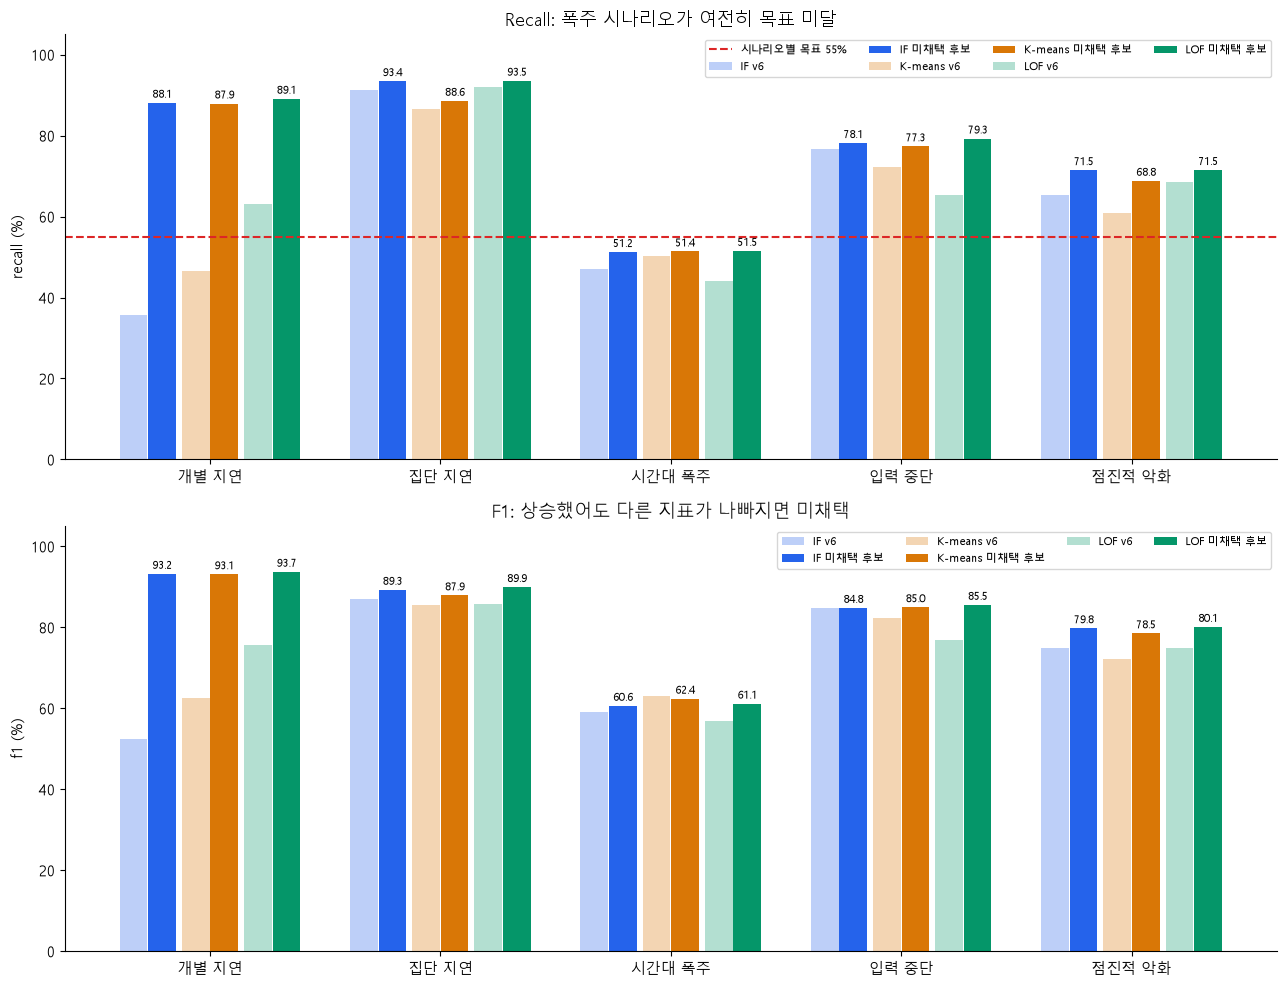

In [6]:
fig,axes=plt.subplots(2,1,figsize=(13,10));x=np.arange(5)
for ax,metric,title in zip(axes,['recall','f1'],['Recall: 폭주 시나리오가 여전히 목표 미달','F1: 상승했어도 다른 지표가 나빠지면 미채택']):
    for i,(a,name,color)in enumerate(zip(alg,names,['#2563eb','#d97706','#059669'])):
        old=[next(r for r in d['metrics']if r['method']==a)[metric]*100 for d in s['datasets']]
        new=[next(r for r in d['metrics']if r['method']==a)[metric]*100 for d in candidate['datasets']]
        pos=x+(i-1)*.27
        ax.bar(pos-.062,old,width=.12,color=color,alpha=.3,label=name+' v6')
        bars=ax.bar(pos+.062,new,width=.12,color=color,label=name+' 미채택 후보');ax.bar_label(bars,fmt='%.1f',fontsize=8,padding=2)
    if metric=='recall':ax.axhline(55,color='#dc2626',linestyle='--',label='시나리오별 목표 55%')
    ax.set(xticks=x,xticklabels=labels,ylim=(0,105),ylabel=metric+' (%)',title=title);ax.legend(ncol=4,fontsize=8)
fig.tight_layout();fig.savefig(OUT/'full_candidate_comparison.png',dpi=150,bbox_inches='tight');display(fig);plt.close(fig)

### 요청한 강점이 실제로 나타났나?

IF의 개별 지연과 K-means의 집단 지연은 v6보다 개선됐으나 이 후보의 세 모델 중 1위는 아니다. LOF는 점진적 악화 F1이 조금 더 높지만 유의한 우위로 확정하지 않는다. 다른 모델을 낮춰 순위를 만들지 않는다. 다음 선택은 사례 집단을 키우고 **각 시나리오의 오탐률까지 기존보다 증가하지 않는지** 확인한다.

In [7]:
display(pd.DataFrame(candidate['requested_roles']['requested_roles']).rename(columns={'F1_gap_to_best_other_pp':'다른 최고 모델 대비 F1 차이(%p)','observed_best_F1':'관측 F1 최고'}).round(4))

,requested_model,task,F1,Precision,Recall,다른 최고 모델 대비 F1 차이(%p),관측 F1 최고,not_statistical_significance_claim
0,if,individual_delay,0.9320,0.9892,0.8810,-0.5130,False,True
1,kmeans,group_delay,0.8788,0.8719,0.8857,-2.0535,False,True
2,lof,gradual_degradation,0.8010,0.9108,0.7148,0.3463,True,True


## 9. 요청 역할을 우선한 두 번째 전체 평가 — 아직 미채택

이 후보는 정상 요청 수 PMF 기반의 과거 방향 상태 피처를 추가하고, IF는 개별 지연·K-means는 집단 지연·LOF는 점진적 악화 F1을 선택 목표로 삼았다. 같은 추정기의 기존 점수와 통계 결합 점수 중 관측 집단별 방식을 선택한다. **모델 자체의 보편적 강점이 확인됐다는 뜻은 아니다.**

세 모델의 모든 시나리오 Recall이 55%를 넘었다. 그러나 폭주의 오탐률, 일부 입력 중단 지표는 기존보다 나빠 **전체 조건은 실패**했다. 정상·정답·난이도는 바꾸지 않았다. 독립 지표 재계산과 실제 Process 입력/직렬화/미래 비참조 검증은 통과했지만, 그것이 성능 조건 통과를 뜻하지 않는다.

In [8]:
second=read(OUT/'attempt_pmf02/audited_summary.json')
second_rows=[]
for d in second['datasets']:
    for r in d['metrics']:
        second_rows.append({'시나리오':labels[tasks.index(d['dataset'])],'모델':r['method'],**{k:100*r[k]for k in metrics},'TP':r['tp'],'FP':r['fp'],'FN':r['fn'],'TN':r['tn']})
display(pd.DataFrame(second_rows).round(3))
display(pd.DataFrame(second['requested_roles']['requested_roles']).round(4))
print('전체 목표 달성:',second['all_targets_met'],'/ 기존 v6 유지')

,시나리오,모델,accuracy,precision,recall,f1,normal_false_positive_rate,TP,FP,FN,TN
0,개별 지연,if,99.248,99.153,91.930,95.405,0.073,4682,40,411,54851
1,개별 지연,kmeans,98.401,99.144,81.877,89.687,0.066,4170,36,923,54855
2,개별 지연,lof,97.076,99.791,65.698,79.233,0.013,3346,7,1747,54884
3,집단 지연,if,96.028,84.185,90.847,87.389,3.047,50071,9406,5045,299308
4,집단 지연,kmeans,96.825,91.245,87.432,89.298,1.498,48189,4624,6927,304090
5,집단 지연,lof,96.639,85.419,93.829,89.427,2.860,51715,8828,3401,299886
6,시간대 폭주,if,93.814,79.347,55.126,65.055,1.674,22967,5978,18696,351215
7,시간대 폭주,kmeans,94.167,83.480,55.051,66.348,1.271,22936,4539,18727,352654
8,시간대 폭주,lof,94.072,81.850,55.570,66.197,1.437,23152,5134,18511,352059
9,입력 중단,if,95.471,94.483,75.984,84.230,0.840,60779,3549,19210,418950


,requested_model,task,F1,Precision,Recall,F1_gap_to_best_other_pp,observed_best_F1,not_statistical_significance_claim
0,if,individual_delay,0.9540,0.9915,0.9193,5.7179,True,True
1,kmeans,group_delay,0.8930,0.9124,0.8743,-0.1291,False,True
2,lof,gradual_degradation,0.8073,0.9001,0.7319,4.6718,True,True


전체 목표 달성: False / 기존 v6 유지


### 지금 남은 문제와 추가 검증

- Adapter·과거 완료 이력별 세분된 경보 기준이 1,000개 예비 사례에 과하게 맞춰지는지 확인한다.
- 폭주 기준은 알려진 Adapter 간 공유하는 후보를 추가한다. 소요시간 기준의 Adapter 정보는 유지한다.
- ECDF 상단에서 강한 신호가 같은 값으로 포화되는 문제를 줄이기 위해, 정상 중앙값/P95로 크기를 보존하는 연속 꼬리 점수를 비교한다.
- 극단적 요청 수에서 확률 계산이 너무 작아지는 문제를 막기 위해 로그 공간 계산도 테스트한다. 기존 실험 객체는 이전 계산을 유지하며 새 후보에만 명시적으로 사용한다.
- **합산 상승이나 원하는 순위만으로 채택하지 않는다.** 각 시나리오 Accuracy·Precision·F1·오탐률과 Recall 55%를 모두 다시 검사한다.